In [10]:
#routing路由模式agent
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
from langchain_core.messages import HumanMessage
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.constants import START,END
from langgraph.graph import MessagesState, StateGraph


class IntentState(MessagesState):
    intent : str
load_dotenv()
model = init_chat_model(
    model = 'deepseek-flash',
    extra_body = {"thinking":{"type":"disabled"}}
)

#定义四个节点：查天气、翻译、闲聊、意图识别路由
def weather_node(state:IntentState):
    """查询天气信息"""
    return {"messages":[AIMessage(content= "晴天")]}

def translate_node(state:IntentState):
    """翻译"""
    ai_message = model.invoke(
        [
            SystemMessage(content=f'你是一个翻译专家，根据用户的问题进行翻译'),
            HumanMessage(content=f"用户的问题:{state["messages"][-1].content}")
        ]
    )
    return {'messages':[ai_message]}

def chitchat_node(state:IntentState):
    """闲聊"""
    ai_message = model.invoke(
        [
            SystemMessage(content=f'你是一个热情积极的聊天搭子，以友好态度和用户聊天'),
            *state["messages"]
        ]
    )
    return {"messages":[ai_message]}

#公司用特有微调模型进行意图识别
def route_node(state:IntentState):
    """意图识别的路由节点"""
    ai_message = model.invoke(
        [
            SystemMessage(content="你要根据用户的问题，识别用户的意图，可选的意图只有:weather,translate,chitchat。注意：只输出意图，禁止输出其他任何内容"),
            HumanMessage(content=state["messages"][-1].content)
        ]
    )
    return Command(
        update={"intent":ai_message.content},
        goto=ai_message.text#保证一定是字符串
    )

#构建agent
builder = StateGraph(IntentState)
builder.add_node("weather",weather_node)
builder.add_node("translate",translate_node)
builder.add_node("chitchat",chitchat_node)
builder.add_node("router",route_node)

builder.add_edge(START,"router")
builder.add_edge("weather",END)
builder.add_edge("translate",END)
builder.add_edge("chitchat",END)

agent = builder.compile(checkpointer=InMemorySaver())

#调用智能体
res = agent.invoke(
    input = {"messages":[HumanMessage(content="周六还要上班好累啊我服了")]},
    config = {"configurable":{"thread_id":'t1'}}
)
print(res["messages"][-1].content)



C:\Users\Administrator\AppData\Local\Temp\ipykernel_2776\3578371611.py:5: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools.you import tool


真的懂你这种感觉！周六上班简直是“灵魂拷问”，一周的疲惫还没缓过来就又要继续，谁顶得住啊😩 不过你这么拼，肯定是有目标或者责任心很强的人，先给你鼓个掌👏

今天上班有没有什么特别烦的事，还是纯粹就是“不想动”的累？如果是后一种，咱们可以聊聊周末怎么偷点小快乐，比如点杯好喝的、下班路上听点喜欢的歌，给自己回回血～🍵🎧

再撑一撑，今天过了就是你的时间了！💪

=== xray=True模式（展开子图内部）===


NameError: name 'Image' is not defined

深圳现在是晴天 ☀️ 天气不错，适合外出活动，记得做好防晒哦。需要了解更详细的信息（比如气温、未来几天预报）可以告诉我。

=== xray=True模式（展开子图内部）===


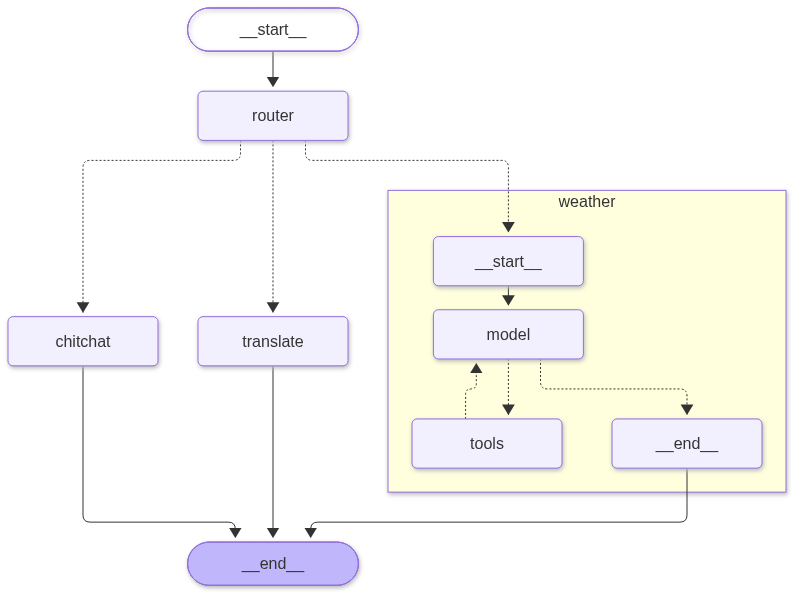

In [14]:
#子图嵌入模式agent

from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
from langchain_core.messages import AIMessage, SystemMessage, HumanMessage
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.constants import START,END
from langgraph.graph import MessagesState, StateGraph
from langgraph.types import Command
from langchain_core.tools import tool
from langchain.agents import create_agent

from IPython.display import Image, display
#准备State类
class IntentState(MessagesState):
    intent : str

load_dotenv()
model = init_chat_model(
    model = 'deepseek-flash',
    extra_body = {"thinking":{"type":"disabled"}}
)

#准备子图，查天气
@tool(description = "根据location查询天气")
def query_weather(location:str)->str:
    return f"{location}的天气是晴天。"
weather_agent = create_agent(
    model = model,
    tools = [query_weather],
    system_prompt="你是一个天气助手",
    checkpointer=InMemorySaver()
)

#定义三个节点：翻译、闲聊、意图识别路由
# def weather_node(state:IntentState):
#     """查询天气信息"""
#     return {"messages":[AIMessage(content= "晴天")]}

def translate_node(state:IntentState):
    """翻译"""
    ai_message = model.invoke(
        [
            SystemMessage(content=f'你是一个翻译专家，根据用户的问题进行翻译'),
            HumanMessage(content=f"用户的问题:{state["messages"][-1].content}")
        ]
    )
    return {'messages':[ai_message]}

def chitchat_node(state:IntentState):
    """闲聊"""
    ai_message = model.invoke(
        [
            SystemMessage(content=f'你是一个热情积极的聊天搭子，以友好态度和用户聊天'),
            *state["messages"]
        ]
    )
    return {"messages":[ai_message]}

#公司用特有微调模型进行意图识别
def route_node(state:IntentState):
    """意图识别的路由节点"""
    ai_message = model.invoke(
        [
            SystemMessage(content="你要根据用户的问题，识别用户的意图，可选的意图只有:weather,translate,chitchat。注意：只输出意图，禁止输出其他任何内容"),
            HumanMessage(content=state["messages"][-1].content)
        ]
    )
    return {"intent": ai_message.content.strip()}

# 新增一个分发函数
def route_decision(state: IntentState) -> str:
    # 直接从 state 中取出刚才保存的意图
    return state["intent"]

#构建agent
builder = StateGraph(IntentState)
builder.add_node("weather",weather_agent)
builder.add_node("translate",translate_node)
builder.add_node("chitchat",chitchat_node)
builder.add_node("router",route_node)

builder.add_edge(START,"router")
builder.add_conditional_edges(
    "router",
    route_decision,
    {
        "weather": "weather",
        "translate": "translate",
        "chitchat": "chitchat"
    }
)
builder.add_edge("weather",END)
builder.add_edge("translate",END)
builder.add_edge("chitchat",END)

agent = builder.compile(checkpointer=InMemorySaver())

#调用智能体
res = agent.invoke(
    input = {"messages":[HumanMessage(content="深圳天气怎么样")]},
    config = {"configurable":{"thread_id":'t1'}}
)
print(res["messages"][-1].content)
print("\n=== xray=True模式（展开子图内部）===")
display(Image(agent.get_graph(xray=True).draw_mermaid_png()))
